# 00 Baseline XGBoost

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set random state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load data
df = pd.read_csv('../dataset/pd_speech_features.csv', header=1)
X = df.drop(['id', 'class'], axis=1)
y = df['class']
groups = df['id']

# Print basic stats
print(f"Data shape: {df.shape}")
print(f"Patients: {groups.nunique()}")


Data shape: (756, 755)
Patients: 252


In [2]:
import xgboost as xgb

def run_xgboost(X, y, groups):
    gkf = GroupKFold(n_splits=5)
    
    metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
    
    for train_idx, test_idx in gkf.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # 1. VarianceThreshold
        vt = VarianceThreshold(threshold=0.01)
        X_train = vt.fit_transform(X_train)
        X_test = vt.transform(X_test)
        
        # 2. StandardScaler
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        
        # 3. SelectKBest
        skb = SelectKBest(f_classif, k=50)
        X_train = skb.fit_transform(X_train, y_train)
        X_test = skb.transform(X_test)
        
        # 4. SMOTE
        smote = SMOTE(random_state=RANDOM_STATE)
        X_train, y_train = smote.fit_resample(X_train, y_train)
        
        # Train XGBoost
        model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE)
        model.fit(X_train, y_train)
        
        # Evaluate
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]
        
        metrics['acc'].append(accuracy_score(y_test, preds))
        metrics['prec'].append(precision_score(y_test, preds))
        metrics['rec'].append(recall_score(y_test, preds))
        metrics['f1'].append(f1_score(y_test, preds))
        metrics['auc'].append(roc_auc_score(y_test, probs))
        
    # Print results
    print("XGBoost 5-Fold Grouped CV Results:")
    for m in metrics:
        print(f"{m.upper()}: {np.mean(metrics[m]):.4f} Â± {np.std(metrics[m]):.4f}")
        
run_xgboost(X, y, groups)


XGBoost 5-Fold Grouped CV Results:
ACC: 0.7752 Â± 0.0396
PREC: 0.8358 Â± 0.0387
REC: 0.8731 Â± 0.0444
F1: 0.8527 Â± 0.0256
AUC: 0.7802 Â± 0.0588


## Full Data SHAP Explainer

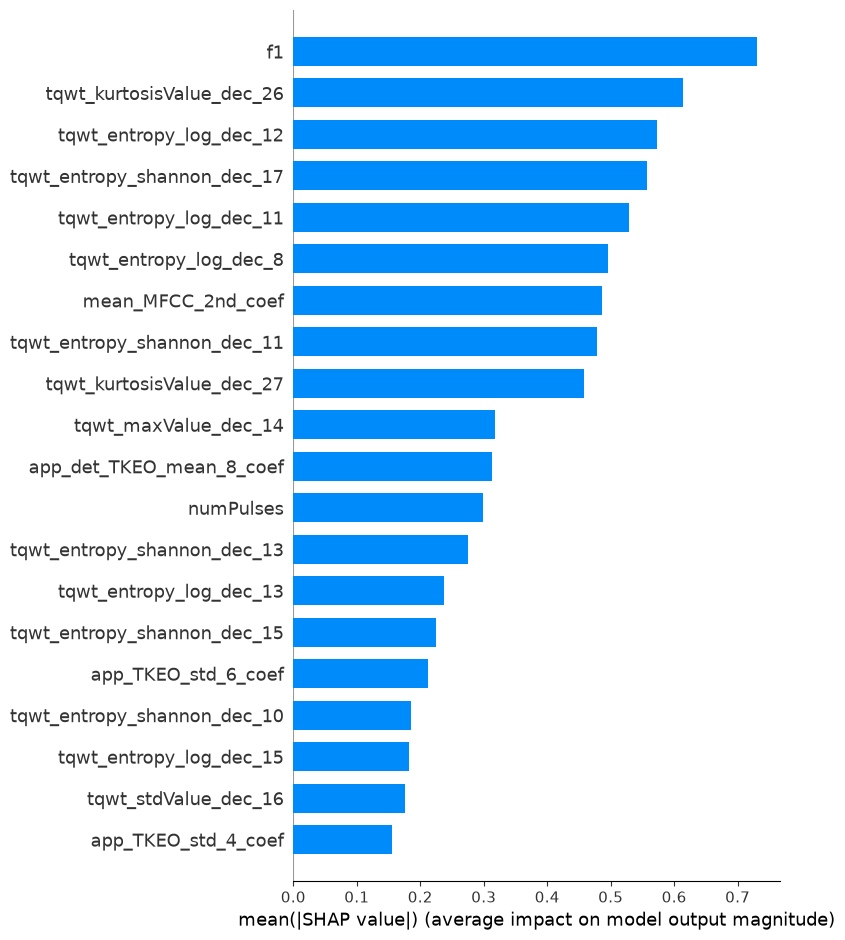

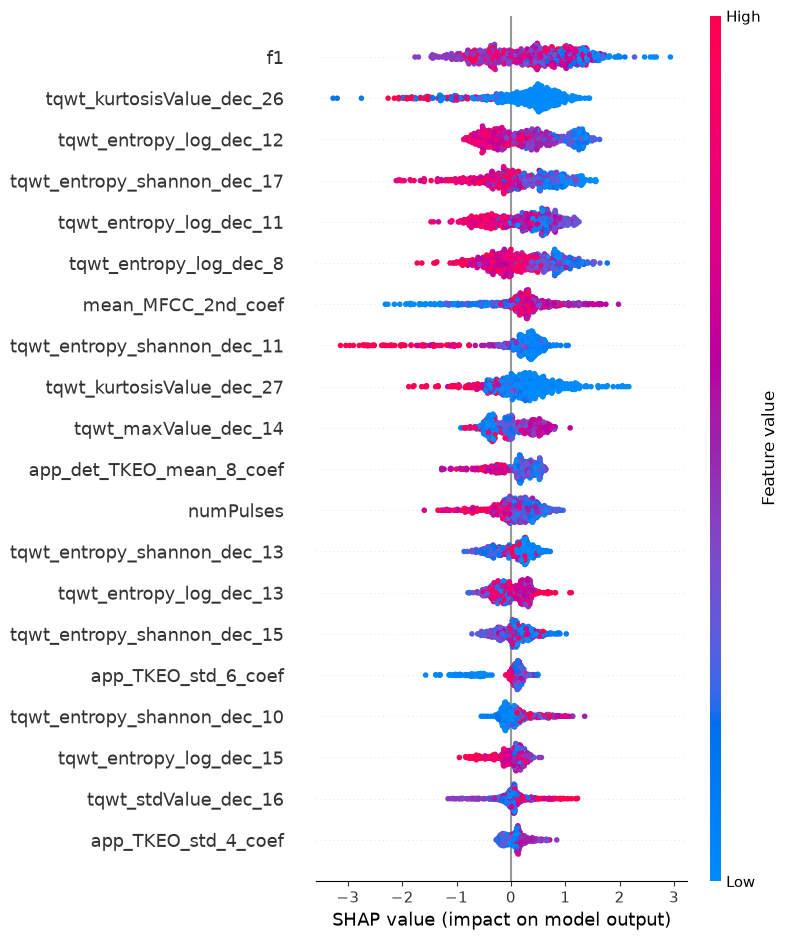

In [3]:
# Fit on full data for SHAP
# 1. VarianceThreshold
vt = VarianceThreshold(threshold=0.01)
X_vt = vt.fit_transform(X)
vt_cols = X.columns[vt.get_support()]

# 2. StandardScaler
scaler = StandardScaler()
X_sc = scaler.fit_transform(X_vt)

# 3. SelectKBest
skb = SelectKBest(f_classif, k=50)
X_skb = skb.fit_transform(X_sc, y)
selected_features = vt_cols[skb.get_support()]

# Create DataFrame with selected feature names
X_final = pd.DataFrame(X_skb, columns=selected_features)

# 4. SMOTE on full data (only for training final SHAP model)
smote = SMOTE(random_state=RANDOM_STATE)
X_res, y_res = smote.fit_resample(X_final, y)

# Final XGBoost Model
model_full = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE)
model_full.fit(X_res, y_res)

# SHAP values
explainer = shap.TreeExplainer(model_full)
shap_values = explainer.shap_values(X_final)

# Plot
plt.figure()
shap.summary_plot(shap_values, X_final, max_display=20, plot_type="bar", show=False)
plt.savefig("xgb_shap_bar.png", bbox_inches='tight')

plt.figure()
shap.summary_plot(shap_values, X_final, max_display=20, plot_type="dot", show=False)
plt.savefig("xgb_shap_beeswarm.png", bbox_inches='tight')
plt.show()
